In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


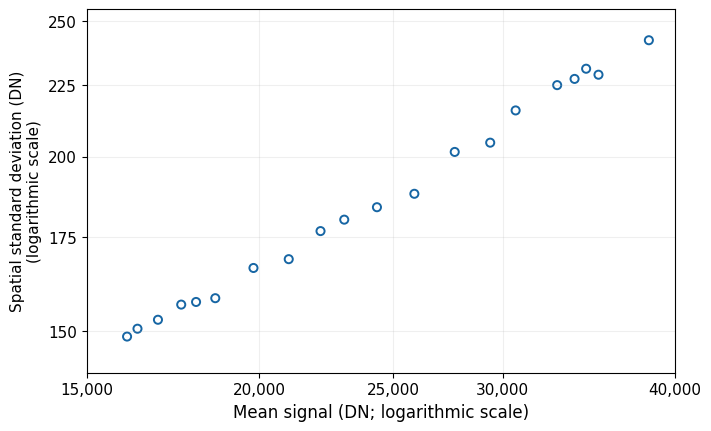

In [2]:
"""Replot the original AstroImageJ sky-flat measurements with readable axes."""
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/astro320-mpl')
import csv
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
folder = DATA
with (folder / 'original_aij_sky_ptc.csv').open() as f:
    rows = list(csv.DictReader(f))
x = [float(r['mean_DN']) for r in rows]
y = [float(r['spatial_SD_DN']) for r in rows]
fig, ax = plt.subplots(figsize=(7, 4.2), layout='constrained')
ax.scatter(x, y, s=34, facecolors='none', edgecolors='#1766a4', linewidths=1.4)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(15000, 40000); ax.set_ylim(140, 255)
ax.xaxis.set_major_locator(FixedLocator([15000, 20000, 25000, 30000, 40000]))
ax.yaxis.set_major_locator(FixedLocator([150, 175, 200, 225, 250]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}'))
ax.xaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_locator(NullLocator())
ax.set_xlabel('Mean signal (DN; logarithmic scale)', fontsize=12)
ax.set_ylabel('Spatial standard deviation (DN)\n(logarithmic scale)', fontsize=11)
ax.tick_params(labelsize=11); ax.grid(alpha=.2)
fig.savefig(OUT / 'sky_flat_PTC.png', dpi=220)
fig.savefig(OUT / 'sky_flat_PTC.pdf')


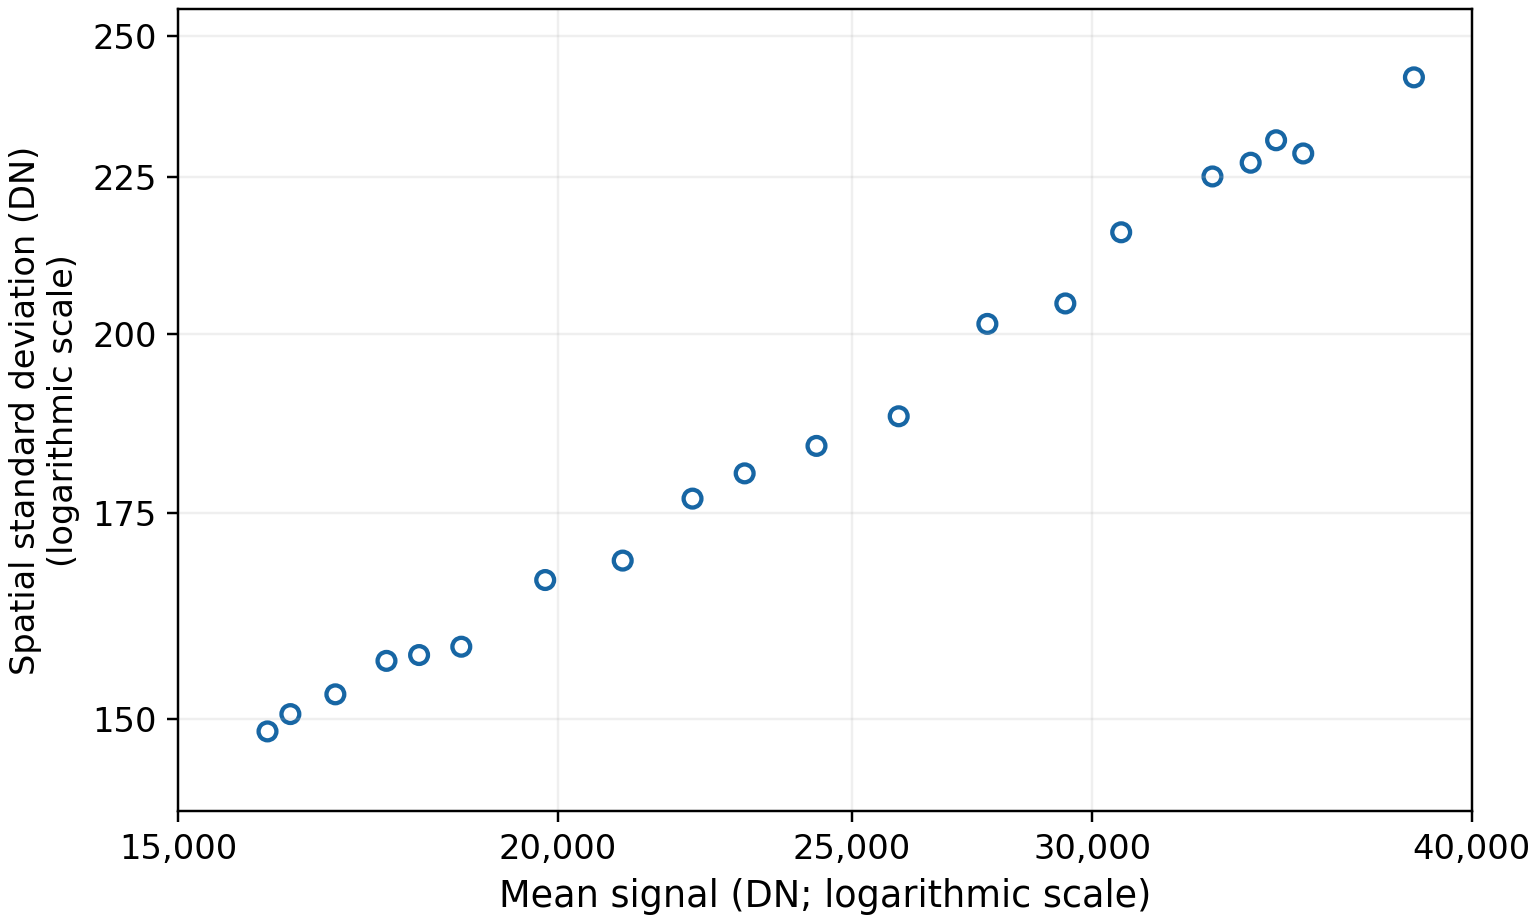

In [3]:
display(Image(filename=str(OUT/'sky_flat_PTC.png')))

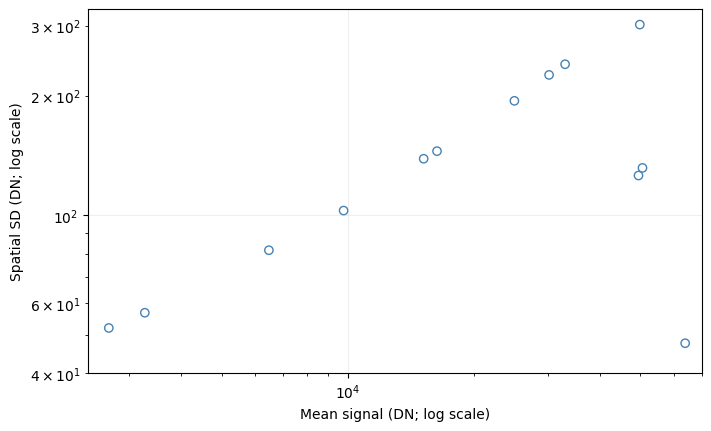

In [4]:
import csv
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
with (DATA/'dome_ptc_digitized.csv').open() as f: r=list(csv.DictReader(f))
x=[float(t['mean_DN_approx']) for t in r]
y=[float(t['spatial_SD_DN_approx']) for t in r]
fig,ax=plt.subplots(figsize=(7,4.2),layout='constrained')
ax.scatter(x,y,facecolors='none',edgecolors='steelblue')
ax.set(xscale='log',yscale='log',xlim=(2400,70000),ylim=(40,330),xlabel='Mean signal (DN; log scale)',ylabel='Spatial SD (DN; log scale)')
ax.grid(alpha=.2)
plt.show()
